# Hackathon 9 — Análisis de la ejecución

Este notebook lee únicamente los CSV descargados de `kaggle/v1/outputs/`: no carga imágenes ni reentrena modelos. Resume la ejecución con cinco folds estratificados sobre 6.000 imágenes y compara tres modelos individuales, el promedio de sus probabilidades y stacking. Las métricas son **macro**: se calcula cada métrica por clase y se promedian las seis clases con igual peso. La desviación estándar corresponde a los cinco folds (muestral, `ddof=1`).

## 1. Cargar los resultados

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ruta = Path('kaggle/v1/outputs')
balance = pd.read_csv(ruta / 'balance.csv')
metricas = pd.read_csv(ruta / 'metricas_por_fold.csv')
historial = pd.read_csv(ruta / 'historial.csv')
predicciones = pd.read_csv(ruta / 'predicciones.csv')
meta = pd.read_csv(ruta / 'dataset_meta.csv')
clases = ['chicken_wings', 'hamburger', 'hot_dog', 'pizza', 'sushi', 'tacos']
modelos = ['ResNet50', 'DenseNet121', 'MobileNetV2']
assert len(balance) == 6 and metricas.groupby('model')['fold'].nunique().eq(5).all()
assert len(predicciones) == predicciones['index'].nunique() == 6000
print(f'{balance.imagenes.sum():,} imágenes; {len(predicciones):,} predicciones externas; {len(meta):,} filas meta.')

6,000 imágenes; 6,000 predicciones externas; 4,800 filas meta.


## 2. Balance entre clases

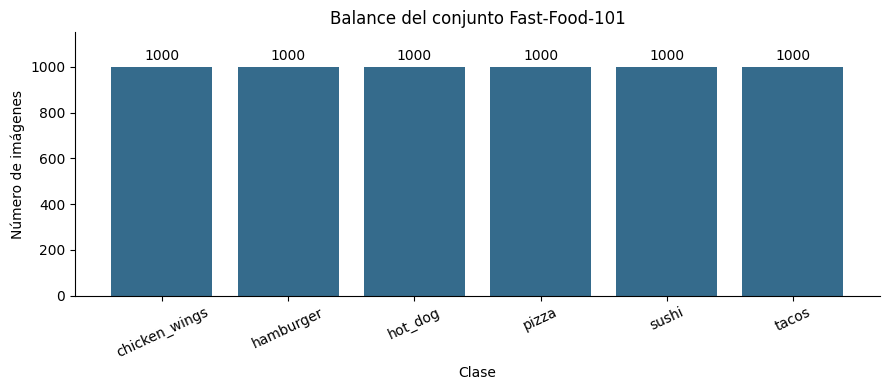

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.bar(balance['label'], balance['imagenes'], color='#356b8c')
ax.bar_label(barras, padding=3)
ax.set(title='Balance del conjunto Fast-Food-101', xlabel='Clase', ylabel='Número de imágenes')
ax.set_ylim(0, balance.imagenes.max() * 1.15)
ax.tick_params(axis='x', rotation=25)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

Cada clase contiene 1.000 imágenes. El conjunto está balanceado en cantidad, aunque esto no garantiza igual dificultad visual ni igual calidad de etiquetas.

## 3. Justificación del preprocesamiento

El procedimiento siguiente describe la ejecución original de Kaggle. Estas transformaciones **no se aplican de nuevo** aquí.

| Técnica | Uso y justificación | Posible aporte a la generalización |
|---|---|---|
| `RandomResizedCrop(224, scale=(0.75, 1.0))` | Entrenamiento: recorta una región de tamaño variable y la redimensiona a 224 × 224, tamaño compatible con las redes. | Expone los modelos a cambios de escala y encuadre. |
| `RandomHorizontalFlip()` | Entrenamiento: refleja algunas imágenes horizontalmente; la categoría de comida suele mantenerse. | Reduce la dependencia de la orientación izquierda-derecha. |
| `ColorJitter(0.15, 0.15, 0.15, 0.05)` | Entrenamiento: variaciones moderadas de brillo, contraste, saturación y tono. | Puede mejorar la tolerancia a iluminación y color diferentes. |
| `Resize(256)` y `CenterCrop(224)` | Meta-validación y fold externo: tamaño fijo y recorte central determinista. | Permite comparar predicciones reproducibles sin aumentos aleatorios en evaluación. |
| `ToTensor()` y normalización ImageNet | Convierte imágenes a tensores y usa media `[0.485, 0.456, 0.406]` y desviación `[0.229, 0.224, 0.225]`. | Adapta la escala de entrada a la usada por los pesos preentrenados. |

Los aumentos solo se aplicaron a entrenamiento. Son hipótesis razonables de robustez: esta ejecución no incluye una ablación que demuestre el aporte de cada técnica.

## 4. Métricas por fold y resumen de cada experimentación

Se muestran Precision y F1 macro para cada fold y, a continuación, su media y desviación estándar entre folds. Las métricas se calcularon sobre el fold externo.

In [3]:
orden = modelos + ['Promedio', 'Stacking']
resumen = (metricas.groupby('model')[['precision_macro', 'f1_macro']]
           .agg(['mean', 'std']).reindex(orden))
resumen.columns = ['Precision mean', 'Precision std', 'F1-score mean', 'F1-score std']
for nombre in modelos + ['Promedio']:
    print(nombre)
    display(metricas.loc[metricas.model.eq(nombre), ['fold', 'precision_macro', 'f1_macro']]
            .rename(columns={'fold':'Fold', 'precision_macro':'Precision macro', 'f1_macro':'F1-score macro'})
            .round(4).reset_index(drop=True))
    display(resumen.loc[[nombre]].round(4))

ResNet50


,Fold,Precision macro,F1-score macro
0,1,0.9121,0.9107
1,2,0.9223,0.9214
2,3,0.9226,0.9222
3,4,0.9229,0.9219
4,5,0.9232,0.9226


,Precision mean,Precision std,F1-score mean,F1-score std
model,,,,
ResNet50,0.9206,0.0048,0.9197,0.0051


DenseNet121


,Fold,Precision macro,F1-score macro
0,1,0.9071,0.9068
1,2,0.9108,0.9107
2,3,0.9096,0.9091
3,4,0.9278,0.9275
4,5,0.9111,0.9107


...

,Fold,Precision macro,F1-score macro
0,1,0.8751,0.8749
1,2,0.8837,0.8826
2,3,0.8933,0.8921
3,4,0.8837,0.8831
4,5,0.8900,0.8895


,Precision mean,Precision std,F1-score mean,F1-score std
model,,,,
MobileNetV2,0.8852,0.007,0.8844,0.0067


Promedio


,Fold,Precision macro,F1-score macro
0,1,0.9178,0.9173
1,2,0.9285,0.9282
2,3,0.9337,0.9333
3,4,0.9325,0.9318
4,5,0.9326,0.9323


,Precision mean,Precision std,F1-score mean,F1-score std
model,,,,
Promedio,0.929,0.0066,0.9286,0.0066


## 5. ¿Cómo se construye y evalúa el stacking?

Para cada fold externo, las imágenes se dividieron en aproximadamente **64 % para entrenar las redes**, **16 % para entrenar el meta-modelo** y **20 % para la evaluación externa**. La división interna fue estratificada.

1. Se entrenaron las tres redes con el 64 %.
2. Cada red produjo seis probabilidades para cada imagen del 16 % reservado. Se concatenaron: **3 modelos × 6 clases = 18 características** por imagen.
3. Una regresión logística se entrenó con esas 18 características y la clase real. `dataset_meta.csv` guarda esas filas, con el fold y el objetivo.
4. Las redes generaron las mismas 18 características para el fold externo. La regresión logística predijo su clase; se calcularon Precision y F1 sobre ese fold.

Para evitar fuga de datos, ninguna imagen del meta-entrenamiento entrenó las redes que produjeron sus probabilidades y el fold externo no se usó para entrenar redes ni meta-modelo. No debe ajustarse el meta-modelo con probabilidades generadas sobre las mismas imágenes usadas para entrenar las redes, ni evaluarlo con filas usadas para ajustarlo. La separación se describe según el código original; los CSV no incluyen los índices internos de entrenamiento/meta, por lo que por sí solos no permiten auditar la separación completa ni los duplicados visuales del dataset.

In [4]:
columnas_prob = [f'{modelo}_{clase}' for modelo in modelos for clase in clases]
assert len(columnas_prob) == 18 and set(columnas_prob).issubset(meta.columns)
print('Ejemplo de una entrada al meta-modelo: 18 probabilidades y su etiqueta')
display(meta[['fold', 'target'] + columnas_prob].head(1).round(4).T.rename(columns={meta.index[0]: 'Valor'}))

Ejemplo de una entrada al meta-modelo: 18 probabilidades y su etiqueta


,Valor
fold,1.0000
target,5.0000
ResNet50_chicken_wings,0.0003
ResNet50_hamburger,0.0015
ResNet50_hot_dog,0.0001
ResNet50_pizza,0.0003
ResNet50_sushi,0.0000
ResNet50_tacos,0.9977
DenseNet121_chicken_wings,0.0004
DenseNet121_hamburger,0.0020


### Métricas del stacking

In [5]:
display(metricas[metricas.model.eq('Stacking')][['fold', 'precision_macro', 'f1_macro']]
        .rename(columns={'fold':'Fold', 'precision_macro':'Precision macro', 'f1_macro':'F1-score macro'})
        .round(4).reset_index(drop=True))
display(resumen.loc[['Stacking']].round(4))

,Fold,Precision macro,F1-score macro
0,1,0.9159,0.9158
1,2,0.9241,0.9241
2,3,0.9325,0.9318
3,4,0.9354,0.9344
4,5,0.9368,0.9366


,Precision mean,Precision std,F1-score mean,F1-score std
model,,,,
Stacking,0.9289,0.0088,0.9285,0.0085


## 6. Reflexión y evidencia

### ¿Qué modelo individual tuvo mejor desempeño?
**ResNet50**, con F1 macro medio de 0,9197 y Precision macro media de 0,9206. Se identifica comparando las medias de los mismos cinco folds externos.

### ¿El stacking mejoró realmente los resultados?
El F1 medio de stacking fue **0,9285**, frente a **0,9197** de ResNet50: una diferencia de **0,0088**, o 0,88 puntos porcentuales. El promedio simple obtuvo **0,9286**, prácticamente lo mismo. La comparación muestra una mejora descriptiva frente al mejor modelo individual; no hay prueba estadística ni conjunto externo independiente que establezca su significancia o generalización fuera de este dataset.

### ¿Qué modelos parecen complementarse mejor?
Se calcula un **acierto de oráculo** por pareja: cuenta una imagen si cualquiera de los dos modelos acierta. Es una medida descriptiva de complementariedad, no un ensemble realizable, porque el oráculo conoce la respuesta correcta.

In [6]:
filas = []
for i, a in enumerate(modelos):
    for b in modelos[i+1:]:
        acierto = ((predicciones[a] == predicciones.truth) | (predicciones[b] == predicciones.truth)).mean()
        filas.append({'Pareja': f'{a} + {b}', 'Acierto de oráculo': acierto})
complemento = pd.DataFrame(filas).sort_values('Acierto de oráculo', ascending=False)
display(complemento.round(4).reset_index(drop=True))

,Pareja,Acierto de oráculo
0,ResNet50 + DenseNet121,0.9515
1,ResNet50 + MobileNetV2,0.9427
2,DenseNet121 + MobileNetV2,0.9412


ResNet50 + DenseNet121 obtiene el mayor acierto de oráculo (0,9515). Esto sugiere mayor complementariedad en esta muestra, pero también depende de la calidad individual de ambos modelos y no demuestra que una combinación práctica vaya a alcanzar ese valor.

### ¿Qué clases generan más errores?

In [7]:
errores = (predicciones.assign(clase=predicciones.truth.map(dict(enumerate(clases))),
                                error=predicciones.Stacking.ne(predicciones.truth))
           .groupby('clase')['error'].agg(['sum', 'count']).rename(columns={'sum':'Errores', 'count':'Imágenes'}))
errores['Tasa de error'] = errores['Errores'] / errores['Imágenes']
display(errores.sort_values('Errores', ascending=False).round(4))

,Errores,Imágenes,Tasa de error
clase,,,
hot_dog,103,1000,0.103
hamburger,88,1000,0.088
tacos,85,1000,0.085
sushi,66,1000,0.066
pizza,47,1000,0.047
chicken_wings,40,1000,0.040


En stacking, **hot_dog** presenta 103 errores de 1.000 imágenes, seguido por **hamburger** (88) y **tacos** (85). Se trata de errores externos acumulados de los cinco folds.

### ¿Qué indica la desviación estándar sobre estabilidad?
La desviación de F1 de ResNet50 es **0,0051**, la de stacking **0,0085** y la del promedio **0,0066**. En estas particiones ResNet50 fue más estable, aunque alcanzó una media menor. La desviación describe variación entre cinco folds; no es una garantía de estabilidad futura ni un intervalo de confianza.

### ¿Existen signos de sobreajuste?
Las siguientes curvas promedian la pérdida por época entre folds. La pérdida de meta-validación usa las imágenes reservadas para entrenar el meta-modelo; no es la pérdida del fold externo. La pérdida de entrenamiento se mide durante el entrenamiento con aumentos, por lo que no es estrictamente comparable con la de evaluación.

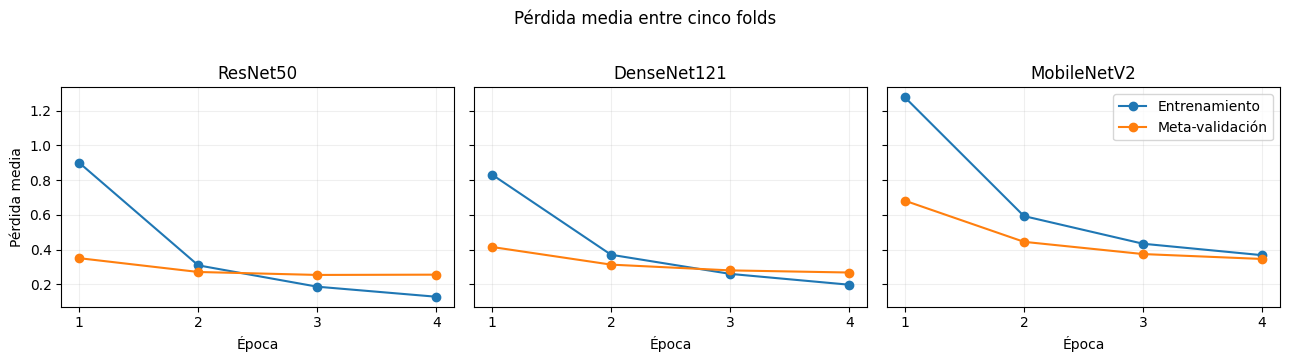

train_loss  meta_loss  train_accuracy  meta_accuracy
model       epoch                                                      
DenseNet121 1          0.8321     0.4147          0.7601         0.8752
            2          0.3699     0.3130          0.8871         0.9002
            3          0.2595     0.2797          0.9232         0.9056
            4          0.1971     0.2675          0.9415         0.9098
MobileNetV2 1          1.2778     0.6817          0.6409         0.8304
            2          0.5930     0.4445          0.8289         0.8675
            3          0.4334     0.3739          0.8643         0.8810
            4          0.3674     0.3456          0.8814         0.8869
ResNet50    1          0.9008     0.3502          0.7397         0.8919
            2          0.3088     0.2706          0.9022         0.9112
            3          0.1857     0.2535          0.9431         0.9208
            4          0.1277     0.2551          0.9608         0.9196

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, nombre in zip(axes, modelos):
    curva = historial[historial.model.eq(nombre)].groupby('epoch')[['train_loss', 'meta_loss']].mean()
    ax.plot(curva.index, curva.train_loss, marker='o', label='Entrenamiento')
    ax.plot(curva.index, curva.meta_loss, marker='o', label='Meta-validación')
    ax.set(title=nombre, xlabel='Época', xticks=curva.index)
    ax.grid(alpha=.2)
axes[0].set_ylabel('Pérdida media')
axes[-1].legend()
fig.suptitle('Pérdida media entre cinco folds', y=1.02)
fig.tight_layout()
plt.show()
display(historial.groupby(['model', 'epoch'])[['train_loss', 'meta_loss', 'train_accuracy', 'meta_accuracy']].mean().round(4))

En ResNet50 la pérdida de entrenamiento baja de 0,1857 a 0,1277 entre las épocas 3 y 4, mientras la de meta-validación sube ligeramente de 0,2535 a 0,2551: es una **señal leve compatible con sobreajuste**, no una conclusión definitiva. En DenseNet121 aparece una brecha entre entrenamiento y meta-validación al final, pero la pérdida de meta-validación sigue bajando; en MobileNetV2 también sigue bajando. Cuatro épocas y promedios entre folds no permiten caracterizar toda la evolución. Para investigar mejor harían falta curvas adicionales o una evaluación independiente; no se requiere reentrenar para esta lectura de los resultados guardados.